# Phase 1 — catalog-based CNN forecasting
## 1. Project introduction
This is a retrospective baseline for probabilistic **future recorded seismicity**, not deterministic earthquake prediction. Only the CNN is developed here. All experiment implementation is in this notebook. Existing waveform datasets and prior experiments are read-only.

## 2. Research reference
[Perol, Gharbi & Denolle (2018), Science Advances](https://doi.org/10.1126/sciadv.1700578), [author project](https://groups.csail.mit.edu/graphics/convnetquake/), [accessible author preprint](https://arxiv.org/pdf/1702.02073).
ConvNetQuake classifies 10-second, three-component, 100-Hz waveform windows. Eight convolution layers use 32 filters, length-three kernels and stride two, followed by class probabilities. Local filters learn signal patterns; stacked layers expand context. Training uses regularized cross-entropy and Adam; evaluation separates event detection from location classification. This depends on existing signals and labeled catalogs, with limited regional generalization. We borrow weight sharing, nonlinear feature extraction and regularization, but use a much smaller network on catalog bins. Its detection results provide no evidence of future forecasting skill. Its waveform normalization, class balancing and noise/location labels are not transferred.

## 3. Forecasting objective
At weekly issue time **t** (UTC midnight), use only records in **[t−90 days, t)**. Predict seven marginal Bernoulli probabilities for recorded **M ≥ 4.5** events: at least one anywhere in [t,t+7d), in [t,t+3d), in [t+3d,t+7d), and in each of four geographic cells over [t,t+7d). Multiple cells/windows may be positive; zero qualifying events gives all-zero labels. A low-magnitude event does not make the target positive.

Use 2011-01-01 onward: the earlier catalog is sparse and strongly magnitude-truncated; 2011 marks a visible reporting-density change in historical data. This is an exploratory coverage decision, not a verified completeness date. Exclude the final partial UTC day. The bounding box is predeclared as latitude [20,32), longitude [86,100), with splits at 26°N and 93°E (SW, SE, NW, NE). It includes adjacent countries, not just administrative Northeast India. Assume catalog coverage within this period; absent records are **not proof of no physical earthquakes**. Publication/ingestion times are absent, so instantaneous historical catalog availability is an explicit retrospective assumption.

Daily bins retain quiet periods, unlike next-event sequences that condition on a future event existing. Weekly issue spacing avoids overlapping target horizons. Ninety days of history balances activity context and data size. Seven-day M4.5 targets remain provisional until training-only support checks below; 14/30-day horizons and thresholds 4/4.5/5 are counted without selecting on test performance.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, random, time, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, brier_score_loss, average_precision_score, precision_score, recall_score
from sklearn.calibration import calibration_curve
from IPython.display import display, Image

# Resolve from notebook directory or repository root, without machine-specific paths.
BASE = Path.cwd()
if not (BASE / 'data wave').exists():
    BASE = BASE / 'cnn' / 'cnn wave'
assert (BASE / 'data wave').is_dir()
ROOT = BASE.parent.parent
SOURCE = ROOT / 'dataset_2.csv'
MEM = BASE / '.agent-memory'
RESULTS = BASE / 'phase1_cnn_results'
CONFIG = dict(seed=42, start='2011-01-01', history_days=90, horizon_days=7,
              stride_days=7, magnitude_threshold=4.5, train_fraction=.70,
              validation_fraction=.15, batch_size=32, max_epochs=100,
              patience=15, learning_rate=.001, weight_decay=.001,
              filters=[16,32], kernels=[5,3], dropout=.25,
              grid_lat=[20,26,32], grid_lon=[86,93,100], version='phase1-v1')
SEED = CONFIG['seed']
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dataset_hash = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
signature = hashlib.sha256((dataset_hash+json.dumps(CONFIG,sort_keys=True)).encode()).hexdigest()[:12]
EXPERIMENT = 'cnn_'+signature
DIRS = {k:RESULTS/k/EXPERIMENT for k in ['models','plots','metrics','reports']}
for p in DIRS.values(): p.mkdir(parents=True,exist_ok=True)
def save_json(path, obj):
    path.write_text(json.dumps(obj,indent=2,default=str,allow_nan=False),encoding='utf-8')
def checkpoint_memory(task, details):
    (MEM/'checkpoint.md').write_text('# Checkpoint — 2026-11-05\n'+task+'\n'+details+'\n',encoding='utf-8')
def savefig(name):
    plt.tight_layout(); plt.savefig(DIRS['plots']/name,dpi=150,bbox_inches='tight'); plt.close()
    display(Image(filename=str(DIRS['plots']/name)))
environment = {p:importlib.metadata.version(p) for p in ['torch','numpy','pandas','scikit-learn','matplotlib','nbformat','nbclient','ipykernel']}
environment.update(python=platform.python_version(),device=str(device),gpu=torch.cuda.get_device_name(0) if device.type=='cuda' else None)
save_json(DIRS['reports']/'environment.json',environment)
print(EXPERIMENT, environment['device'], environment['gpu'])

Matplotlib is building the font cache; this may take a moment.


cnn_b86050c74334 cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 4. Data discovery
The static inventory was produced by `audit_project.py`: 28 CSV/HDF5 files and 19 relevant Python sources, including all simulator stages and older catalog code. It inspects HDF5 structure without loading large trace arrays. The notebook independently checks the forecasting source. A changed source requires a refreshed inventory.

Simulator chain: (1) validate metadata; (2) compute hypocentral distance and constant-velocity P/S arrivals; (3) clean damped P/S synthesis; (4) magnitude scaling, spreading, attenuation and noise; (5) ten-event prototype evaluation; (6) full HDF5 generation; (7) 50-trace QC; (8) frequency-dependent attenuation, dynamic envelopes and calibrated pre-P SNR; (9) improved full-catalog generation; (10) balanced earthquake/noise synthesis; (11) pair-aware **stratified**, rather than chronological, splits and detrending/per-trace or training-global normalization.
Phase 6/9 each store 8,089 × 10,000 traces. Phase 10 stores 16,178 × 10,000; Phase 11 train/validation/test have 11,324/2,426/2,428 traces. These are detection datasets. Simulator configuration retains an obsolete input path; generated metadata actually exists in its output tree. No simulator is rerun.

In [2]:
inventory = json.loads((RESULTS/'reports'/'dataset_inventory.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'path':x['path'],'shape':str(x.get('shape','HDF5; see JSON'))} for x in inventory]))
raw = pd.read_csv(SOURCE)
raw['time'] = pd.to_datetime(raw.origin_time_utc.str.replace(' UTC','',regex=False),utc=True,errors='raise')
core = ['Lat','Long','Depth_km','Magnitude_Value']
assert raw[core+['time']].notna().all().all()
assert np.isfinite(raw[core].to_numpy()).all()
assert raw.time.is_monotonic_increasing
assert not raw.source_id.duplicated().any()
assert not raw.duplicated(['time']+core).any()
assert raw.Lat.between(-90,90).all() and raw.Long.between(-180,180).all()
assert (raw.Depth_km>=0).all()
audit = dict(shape=[len(raw),len(raw.columns)-1], first=str(raw.time.min()), last=str(raw.time.max()),
             missing=raw.isna().sum().to_dict(), duplicate_rows=int(raw.duplicated().sum()),
             duplicate_event_keys=int(raw.duplicated(['time']+core).sum()),
             magnitude_types=raw.Magnitude_Type.value_counts().to_dict(),sha256=dataset_hash)
save_json(DIRS['reports']/'raw_audit.json',audit)
raw[core].describe().to_csv(DIRS['reports']/'distributions.csv')
pd.DataFrame({'column':raw.columns,'dtype':[str(x) for x in raw.dtypes], 'missing':raw.isna().sum().to_numpy()}).to_csv(DIRS['reports']/'schema.csv',index=False)
print('Raw source:',audit['shape'],audit['first'],'to',audit['last'])

,path,shape
0,cnn/cnn wave/data wave/synthetic_waveform_simu...,HDF5; see JSON
1,cnn/cnn wave/data wave/synthetic_waveform_simu...,"[16178, 10]"
2,cnn/cnn wave/data wave/synthetic_waveform_simu...,"[16178, 13]"
3,cnn/cnn wave/data wave/synthetic_waveform_simu...,"[5, 5]"
4,cnn/cnn wave/data wave/synthetic_waveform_simu...,"[16178, 7]"
5,cnn/cnn wave/data wave/synthetic_waveform_simu...,HDF5; see JSON
6,cnn/cnn wave/data wave/synthetic_waveform_simu...,HDF5; see JSON
7,cnn/cnn wave/data wave/synthetic_waveform_simu...,HDF5; see JSON
8,cnn/cnn wave/data wave/synthetic_waveform_simu...,"[8, 11]"
9,cnn/cnn wave/data wave/synthetic_waveform_simu...,"[8089, 42]"


Raw source: [8089, 28] 1906-08-31 14:57:30+00:00 to 2026-10-06 09:03:32+00:00


## 5. Dataset inspection
The raw CSV contains origin timestamps, magnitude/value/type, coordinates/depth, duplicate source metadata fields, descriptive geography, receiver metadata, arrivals, SNR and trace identifiers. Use only time, magnitude, latitude, longitude and depth. ID uniqueness is checked alongside physical event keys; no imputation or deduplication silently alters the source. Magnitude scales are mixed and not calibrated to Mw.

## 6. Exploratory data analysis
Annual counts include years with zero records. The last year is partial. Magnitude medians and threshold counts reveal reporting changes but do not establish a magnitude-of-completeness estimate. Full-catalog EDA is descriptive; target support decisions use the training period. Since this catalog was inspected during development, this is an exploratory holdout, not an untouched prospective validation.

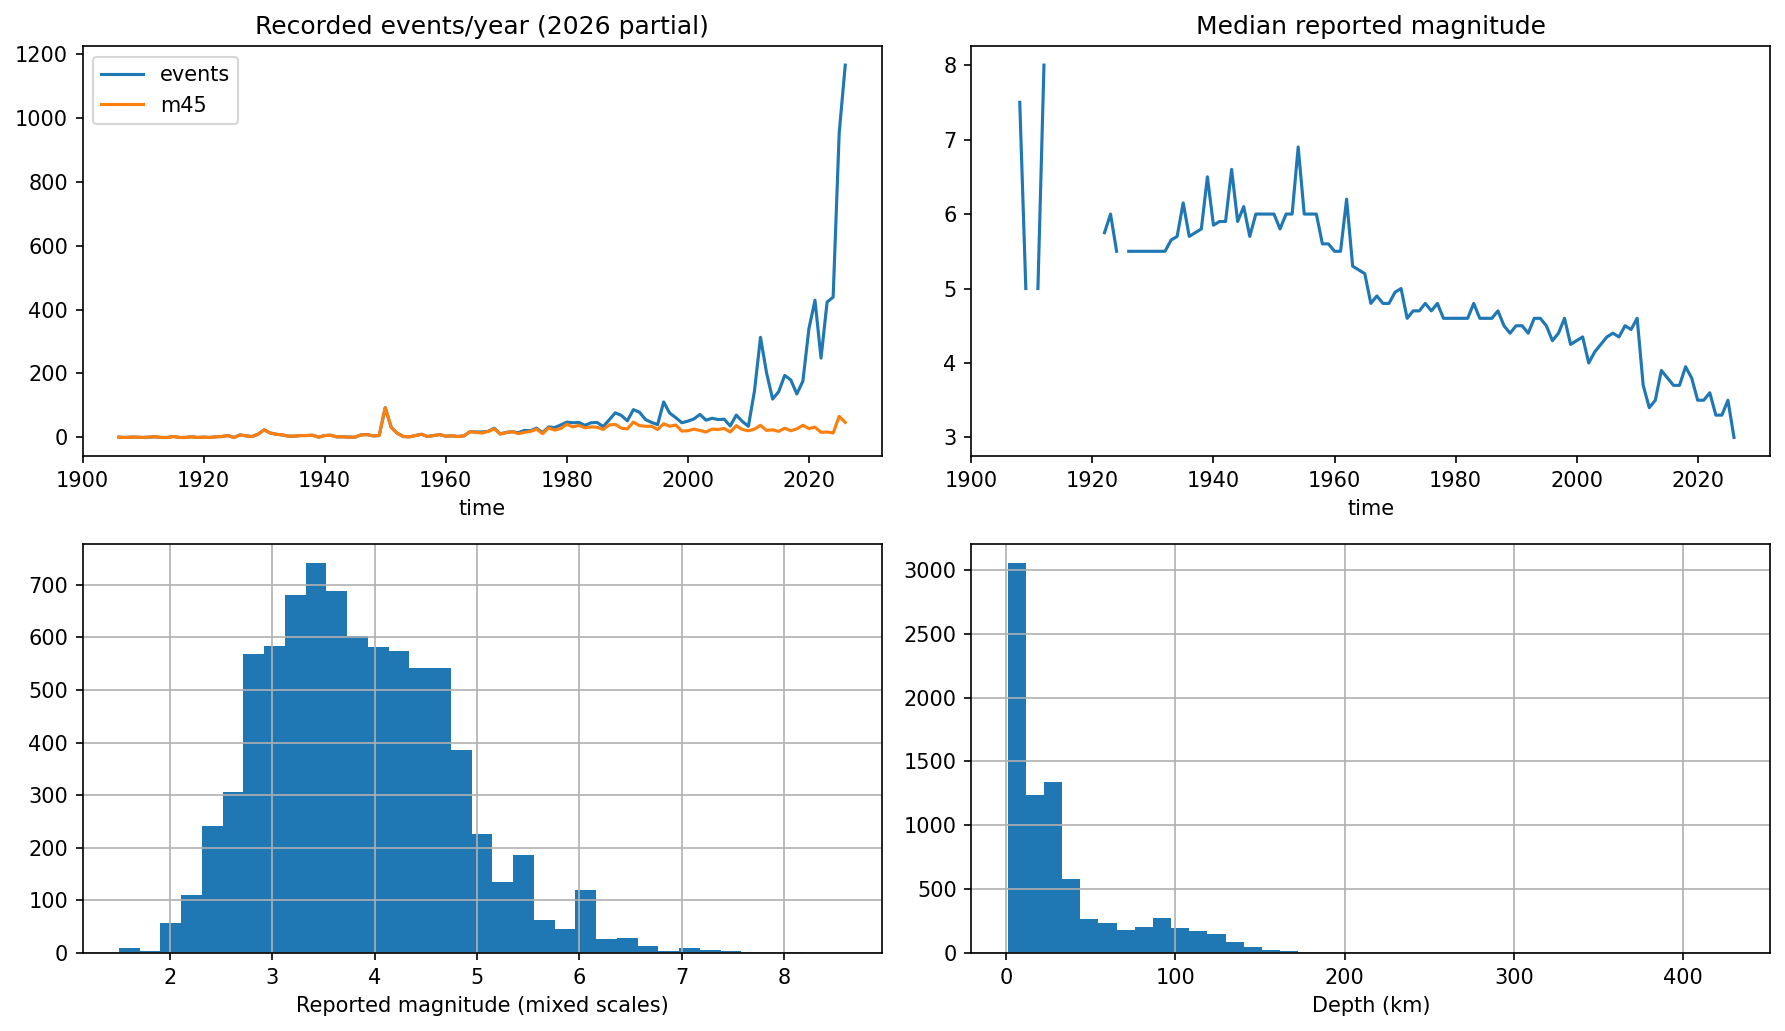

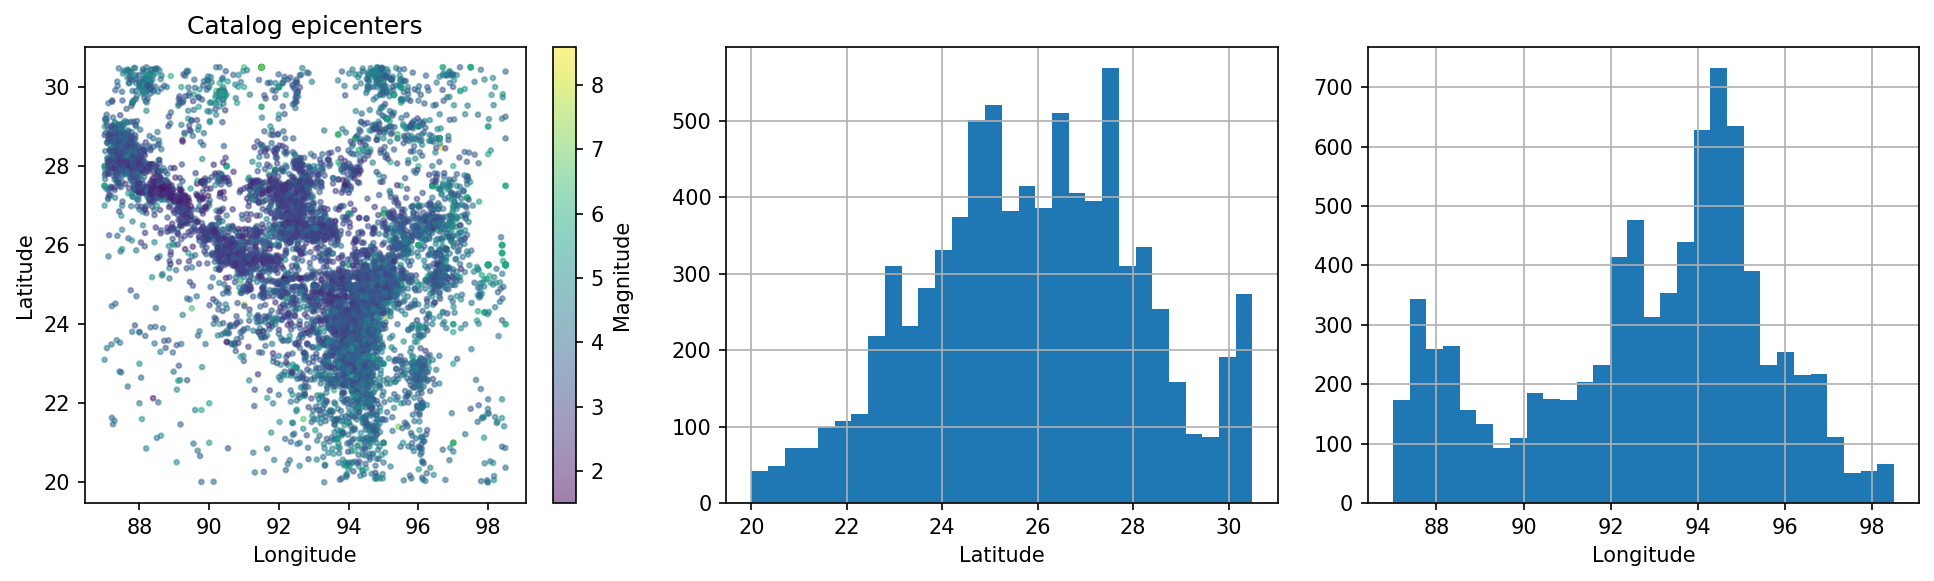

Magnitude types: {'ML': 7125, 'MB': 458, 'MW': 398, 'MC': 107, 'MS': 1}


In [3]:
annual = raw.groupby(raw.time.dt.year).agg(events=('Magnitude_Value','size'),
    median_magnitude=('Magnitude_Value','median'), m45=('Magnitude_Value',lambda x:(x>=4.5).sum()))
annual=annual.reindex(range(raw.time.dt.year.min(),raw.time.dt.year.max()+1))
annual[['events','m45']]=annual[['events','m45']].fillna(0)
annual.to_csv(DIRS['reports']/'annual_counts.csv')
fig,axes=plt.subplots(2,2,figsize=(12,7))
annual[['events','m45']].plot(ax=axes[0,0]); axes[0,0].set_title('Recorded events/year (2026 partial)')
annual.median_magnitude.plot(ax=axes[0,1]); axes[0,1].set_title('Median reported magnitude')
raw.Magnitude_Value.hist(bins=35,ax=axes[1,0]); axes[1,0].set_xlabel('Reported magnitude (mixed scales)')
raw.Depth_km.hist(bins=40,ax=axes[1,1]); axes[1,1].set_xlabel('Depth (km)')
savefig('catalog_eda.png')
fig,axes=plt.subplots(1,3,figsize=(13,4))
sc=axes[0].scatter(raw.Long,raw.Lat,c=raw.Magnitude_Value,s=5,cmap='viridis',alpha=.5)
axes[0].set(xlabel='Longitude',ylabel='Latitude',title='Catalog epicenters'); fig.colorbar(sc,ax=axes[0],label='Magnitude')
raw.Lat.hist(bins=30,ax=axes[1]); axes[1].set_xlabel('Latitude')
raw.Long.hist(bins=30,ax=axes[2]); axes[2].set_xlabel('Longitude')
savefig('catalog_geography.png')
print('Magnitude types:',audit['magnitude_types'])

## 7. Leakage audit
Reject synthetic target-event traces: amplitude/envelope depend on the target magnitude and distance; arrivals depend on target origin/location/depth. Phase 11 pairing protection does not make these forecasts. Reject existing normalized CSVs: `preprocess_dl_temporal.py` computes a full-catalog 99th-percentile gap cap, imputation, encodings and MinMax scaling before splitting. The earlier CNN is a next-event magnitude classifier with overlapping event histories, not a fixed-horizon occurrence forecast.

Here all bins are left-closed/right-open; input ends strictly before t and target starts at t. No centered windows, future IDs, station/arrival/SNR inputs or learned geographic boundaries. Split boundaries use calendar duration. A whole input-plus-target interval must lie inside its assigned partition, sacrificing 90 days of context at each boundary. Shared histories **within** partitions are allowed and create dependence. Training-fitted scaling is applied unchanged. Validation selects the checkpoint; test labels never enter optimizer, scheduler or stopping decisions.

## 8. Input and target construction
Twelve daily features: event count, M≥4 count, M≥4.5 count, maximum magnitude, mean magnitude, mean depth, mean latitude, mean longitude, and four cell event counts. Empty-bin statistics are zero with event count distinguishing absence. Counts are log1p-transformed, then all channels standardized using unique training-history days only. No interpolation across quiet days.

In [4]:
START=pd.Timestamp(CONFIG['start'],tz='UTC')
END=raw.time.max().floor('D')  # exclusive: discard final partially observed day
days=pd.date_range(START,END,freq='D',inclusive='left')
n_days=len(days); H=CONFIG['history_days']; F=CONFIG['horizon_days']
b1=START+pd.Timedelta(days=int(n_days*.70))
b2=START+pd.Timedelta(days=int(n_days*.85))
bounds={'train':(START,b1),'validation':(b1,b2),'test':(b2,END)}
events=raw[(raw.time>=START)&(raw.time<END)].copy()
in_box=events.Lat.ge(20)&events.Lat.lt(32)&events.Long.ge(86)&events.Long.lt(100)
assert in_box.all(), 'Out-of-domain records require an explicit exclusion decision'
events['day']=events.time.dt.floor('D')
events['cell']=(events.Lat.ge(26).astype(int)*2+events.Long.ge(93).astype(int))
group=events.groupby('day')
daily=group.agg(count=('Magnitude_Value','size'), m4=('Magnitude_Value',lambda x:(x>=4).sum()),
    m45=('Magnitude_Value',lambda x:(x>=4.5).sum()), max_mag=('Magnitude_Value','max'),
    mean_mag=('Magnitude_Value','mean'), mean_depth=('Depth_km','mean'),
    mean_lat=('Lat','mean'),mean_lon=('Long','mean')).reindex(days).fillna(0)
for c in range(4): daily[f'cell_{c}_count']=events[events.cell==c].groupby('day').size().reindex(days,fill_value=0)
qualifying=events[events.Magnitude_Value>=CONFIG['magnitude_threshold']]
q=np.stack([qualifying[qualifying.cell==c].groupby('day').size().reindex(days,fill_value=0).to_numpy() for c in range(4)],axis=1)
FEATURES=list(daily.columns)
TARGETS=['M45_any_7d','M45_days_0_3','M45_days_3_7','M45_SW_7d','M45_SE_7d','M45_NW_7d','M45_NE_7d']
Xraw=[]; Y=[]; starts=[]; records=[]
for i in range(H,n_days-F+1,CONFIG['stride_days']):
    t=days[i]; hist=t-pd.Timedelta(days=H); end=t+pd.Timedelta(days=F)
    partition=next((k for k,(lo,hi) in bounds.items() if hist>=lo and end<=hi),None)
    if partition is None: continue  # purge cross-boundary histories/targets
    Xraw.append(daily.iloc[i-H:i].to_numpy())
    Y.append([q[i:i+F].sum()>0,q[i:i+3].sum()>0,q[i+3:i+F].sum()>0,*((q[i:i+F].sum(axis=0)>0).tolist())])
    starts.append(i)
    records.append(dict(issue_time=t,history_start=hist,target_end=end,partition=partition))
Xraw=np.asarray(Xraw,dtype=np.float32); Y=np.asarray(Y,dtype=np.float32); starts=np.asarray(starts)
manifest=pd.DataFrame(records)
idx={k:np.flatnonzero(manifest.partition.eq(k)) for k in bounds}
assert Xraw.shape[1:]==(90,12) and Y.shape==(len(Xraw),7)
assert np.array_equal(Y[:,0],np.any(Y[:,3:]>0,axis=1))
assert np.array_equal(Y[:,0],np.any(Y[:,1:3]>0,axis=1))
assert np.isfinite(Xraw).all()
# Train-only support comparisons: nonoverlapping horizons on the training calendar.
support=[]
for m in [4.,4.5,5.]:
    counts=events[events.Magnitude_Value>=m].groupby('day').size().reindex(days,fill_value=0).to_numpy()
    for horizon in [7,14,30]:
        windows=[counts[i:i+horizon].sum() for i in range(H,(b1-START).days-horizon+1,horizon)]
        support.append(dict(magnitude=m,horizon_days=horizon,windows=len(windows),
                            positive_windows=int(np.count_nonzero(windows)),events=int(sum(windows))))
support=pd.DataFrame(support); support.to_csv(DIRS['reports']/'training_target_support.csv',index=False)
display(support)
assert Y[idx['train'],0].sum()>=30, 'Insufficient training positives: revise design before fitting'
print('Selected events:',len(events),'qualifying:',len(qualifying),'input',Xraw.shape,'targets',Y.shape)

,magnitude,horizon_days,windows,positive_windows,events
0,4.0,7,562,392,768
1,4.0,14,281,257,768
2,4.0,30,131,131,767
3,4.5,7,562,212,296
4,4.5,14,281,171,296
5,4.5,30,131,114,296
6,5.0,7,562,75,86
7,5.0,14,281,71,86
8,5.0,30,131,62,86


Selected events: 5603 qualifying: 464 input (782, 90, 12) targets (782, 7)


## 9. Chronological train/validation/test split
Calendar proportions are 70/15/15 before purging; retained sample proportions differ. The table below records exact boundaries, event counts and target support. Weekly targets do not overlap. All-zero targets are preserved. Every target is rechecked directly against raw event timestamps, independently of the daily-count label implementation.

In [5]:
split_report={}
for name,(lo,hi) in bounds.items():
    ii=idx[name]; part=manifest.iloc[ii]
    assert len(ii)>0 and part.history_start.min()>=lo and part.target_end.max()<=hi
    assert (part.issue_time+pd.Timedelta(days=F)==part.target_end).all()
    assert (part.issue_time-part.history_start==pd.Timedelta(days=H)).all()
    assert (part.issue_time.iloc[1:].reset_index(drop=True)>=part.target_end.iloc[:-1].reset_index(drop=True)).all()
    in_period=events.time.ge(lo)&events.time.lt(hi)
    in_targets=np.zeros(len(events),dtype=bool)
    for row in part.itertuples(): in_targets |= (events.time.ge(row.issue_time)&events.time.lt(row.target_end)).to_numpy()
    split_report[name]=dict(period_start=str(lo),period_end_exclusive=str(hi),
        first_issue=str(part.issue_time.min()),last_issue=str(part.issue_time.max()),
        last_target_end=str(part.target_end.max()),samples=len(ii),catalog_events=int(in_period.sum()),
        target_events=int(in_targets.sum()),target_m45_events=int((in_targets & events.Magnitude_Value.ge(4.5).to_numpy()).sum()),
        positives=Y[ii].sum(axis=0).astype(int).tolist(),negative_primary=int((Y[ii,0]==0).sum()))
for a,b in [('train','validation'),('validation','test')]:
    assert manifest.iloc[idx[a]].target_end.max()<=manifest.iloc[idx[b]].history_start.min()
for j,row in enumerate(manifest.itertuples()):
    future=qualifying[qualifying.time.ge(row.issue_time)&qualifying.time.lt(row.target_end)]
    mid=row.issue_time+pd.Timedelta(days=3)
    expected=[len(future)>0,future.time.lt(mid).any(),future.time.ge(mid).any(),*[future.cell.eq(c).any() for c in range(4)]]
    assert np.array_equal(Y[j],expected)
manifest.to_csv(DIRS['reports']/'split_manifest.csv',index=False)
save_json(DIRS['reports']/'split_summary.json',split_report)
display(pd.DataFrame(split_report).T[['samples','first_issue','last_target_end','catalog_events','target_m45_events','negative_primary']])
checkpoint_memory('T5 dataset preparation completed; T6 implementation ready.',
                  f'Input {Xraw.shape}; output {Y.shape}. Exact split/label assertions passed. Experiment {EXPERIMENT}. Next: train CNN.')

,samples,first_issue,last_target_end,catalog_events,target_m45_events,negative_primary
train,562,2011-04-01 00:00:00+00:00,2022-01-07 00:00:00+00:00,2390,296,350
validation,110,2022-04-15 00:00:00+00:00,2024-05-24 00:00:00+00:00,839,33,81
test,110,2024-08-23 00:00:00+00:00,2026-10-02 00:00:00+00:00,2374,114,48


## 10. Feature preprocessing
Fit the StandardScaler on the union of days actually used in training histories, counting each day once. No validation/test moments, global clipping thresholds or all-catalog normalization are used. Save the exact feature order, fixed transforms, means/scales and domain specification. Inference must recreate the same bins; missing catalog coverage cannot be silently interpreted as zero seismicity.

In [6]:
count_cols=[FEATURES.index(c) for c in ['count','m4','m45','cell_0_count','cell_1_count','cell_2_count','cell_3_count']]
transformed=daily.to_numpy(dtype=np.float64).copy()
transformed[:,count_cols]=np.log1p(transformed[:,count_cols])
training_days=np.unique(np.concatenate([np.arange(starts[j]-H,starts[j]) for j in idx['train']]))
assert days[training_days].max()<b1
scaler=StandardScaler().fit(transformed[training_days])
scaled=scaler.transform(transformed).astype(np.float32)
X=np.stack([scaled[i-H:i].T for i in starts]) # PyTorch: batch, channels, time
assert np.allclose(scaler.mean_,transformed[training_days].mean(axis=0))
assert np.isfinite(X).all()
preprocessing=dict(features=FEATURES,log1p_columns=[FEATURES[i] for i in count_cols],mean=scaler.mean_.tolist(),
                   scale=scaler.scale_.tolist(),n_fit_days=len(training_days),
                   fit_first_day=str(days[training_days].min()),fit_last_day=str(days[training_days].max()),
                   empty_bin_value=0,history_days=H,targets=TARGETS,config=CONFIG,dataset_sha256=dataset_hash)
save_json(DIRS['models']/'preprocessing.json',preprocessing)
save_json(DIRS['reports']/'config.json',CONFIG)
np.savez_compressed(DIRS['reports']/'forecast_dataset.npz',X=X,Y=Y,issue_day_index=starts,**idx)
print('Model input:',X.shape,'training-only scaler days:',len(training_days))

Model input: (782, 12, 90) training-only scaler days: 4017


## 11. CNN architecture
Input (12 channels, 90 days) → Conv1D(12→16, kernel 5, padding 2) learns local five-day patterns → BatchNorm stabilizes learned activations using training statistics → ReLU → Conv1D(16→32, kernel 3, padding 1) combines patterns over a seven-day receptive field → ReLU → global mean pooling summarizes the 90-day history → Dense(32→16), ReLU and dropout 0.25 → seven logits. Sigmoid converts each logit to an occurrence probability.

Padding uses zeros inside the **past-only** input; it cannot access events after t. Global pooling sacrifices exact within-history timing, an intentional baseline limitation. Outputs are separate marginal forecasts, not a normalized location distribution or a coherent joint event process; their unions need not agree. Report this limitation rather than treating cell probabilities as summing to one.

## 12. Model compilation
PyTorch has no separate compile step. Use mean unweighted BCEWithLogitsLoss across seven binary targets, AdamW at 0.001 with weight decay 0.001, batch size 32, at most 100 epochs. No SMOTE/class weighting distorts occurrence probabilities. Initialize biases from smoothed training prevalence. Monitor mean validation BCE, halve learning rate after five stagnant epochs, stop after fifteen, and restore the best validation checkpoint. Model configuration is fixed before test evaluation.

In [7]:
class CatalogCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv1d(12,16,5,padding=2),nn.BatchNorm1d(16),nn.ReLU(),
                                    nn.Conv1d(16,32,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool1d(1))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(32,16),nn.ReLU(),nn.Dropout(.25),nn.Linear(16,7))
    def forward(self,x): return self.head(self.features(x))
model=CatalogCNN().to(device)
prior=(Y[idx['train']].sum(axis=0)+.5)/(len(idx['train'])+1)
with torch.no_grad(): model.head[-1].bias.copy_(torch.tensor(np.log(prior/(1-prior)),device=device))
n_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad)
assert model(torch.tensor(X[:2],device=device)).shape==(2,7)
# Reset BN running statistics after the shape probe.
model.features[1].reset_running_stats()
criterion=nn.BCEWithLogitsLoss()
optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG['learning_rate'],weight_decay=CONFIG['weight_decay'])
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.5,patience=5)
loader_generator=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(TensorDataset(torch.from_numpy(X[idx['train']]),torch.from_numpy(Y[idx['train']])),
                        batch_size=CONFIG['batch_size'],shuffle=True,num_workers=0,generator=loader_generator)
def predict(indices):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X[indices]).to(device))).cpu().numpy()
print(model); print('Trainable parameters:',n_parameters)
(DIRS['reports']/'model_architecture.txt').write_text(str(model)+f'\nTrainable parameters: {n_parameters}\n',encoding='utf-8')

CatalogCNN(
  (features): Sequential(
    (0): Conv1d(12, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): AdaptiveAvgPool1d(output_size=1)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32, out_features=16, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=16, out_features=7, bias=True)
  )
)
Trainable parameters: 3223


615

## 13. Training
Only training batches are shuffled; partition assignments remain chronological. `last.pt` saves model, optimizer, scheduler, random-generator states and history after each epoch, enabling continuation. `best.pt` is the lowest validation BCE checkpoint. Re-execution of an already completed configuration restores its model without silently repeating the experiment. Training is a single prespecified seed; results are not chosen from seed trials.

In [8]:
best_path=DIRS['models']/'best.pt'; last_path=DIRS['models']/'last.pt'
history=[]; best=float('inf'); stale=0; first_epoch=1; completed=False
if last_path.exists():
    state=torch.load(last_path,map_location=device,weights_only=False) # own local checkpoint only
    assert state['config']==CONFIG and state['dataset_sha256']==dataset_hash
    model.load_state_dict(state['model']); optimizer.load_state_dict(state['optimizer']); scheduler.load_state_dict(state['scheduler'])
    history=state['history']; best=state['best']; stale=state['stale']; first_epoch=state['epoch']+1; completed=state['completed']
    random.setstate(state['python_rng']); np.random.set_state(state['numpy_rng'])
    torch.set_rng_state(state['torch_rng'].cpu()); loader_generator.set_state(state['loader_rng'].cpu())
    if device.type=='cuda' and state['cuda_rng'] is not None: torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda_rng']])
    print('Restoring epoch',state['epoch'],'completed=',completed)
registry=json.loads((MEM/'experiment_registry.json').read_text())
entry=dict(experiment_id=EXPERIMENT,model_type='1D CNN',dataset_version=dataset_hash,
           input_features=FEATURES,forecast_horizon_days=F,date_ranges=split_report,hyperparameters=CONFIG,
           random_seed=SEED,model_checkpoint_path=str(best_path.relative_to(BASE)),
           metrics_path=str((DIRS['metrics']/'scores.csv').relative_to(BASE)),experiment_status='training')
registry['experiments']=[e for e in registry['experiments'] if e['experiment_id']!=EXPERIMENT]+[entry]
save_json(MEM/'experiment_registry.json',registry)
for epoch in ([] if completed else range(first_epoch,CONFIG['max_epochs']+1)):
    model.train(); total=0.; seen=0
    for xb,yb in train_loader:
        xb=xb.to(device); yb=yb.to(device); optimizer.zero_grad(set_to_none=True)
        loss=criterion(model(xb),yb); loss.backward(); optimizer.step()
        total+=loss.item()*len(xb); seen+=len(xb)
    model.eval()
    with torch.no_grad():
        val_loss=criterion(model(torch.from_numpy(X[idx['validation']]).to(device)),torch.from_numpy(Y[idx['validation']]).to(device)).item()
    train_loss=total/seen
    assert np.isfinite([train_loss,val_loss]).all()
    improved=val_loss<best-1e-6
    if improved:
        best=val_loss; stale=0
        torch.save(dict(model=model.state_dict(),epoch=epoch,val_loss=best,config=CONFIG,dataset_sha256=dataset_hash),best_path)
    else: stale+=1
    scheduler.step(val_loss)
    history.append(dict(epoch=epoch,train_bce=train_loss,validation_bce=val_loss,learning_rate=optimizer.param_groups[0]['lr']))
    completed=stale>=CONFIG['patience'] or epoch==CONFIG['max_epochs']
    state=dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),
               epoch=epoch,history=history,best=best,stale=stale,completed=completed,config=CONFIG,dataset_sha256=dataset_hash,
               python_rng=random.getstate(),numpy_rng=np.random.get_state(),torch_rng=torch.get_rng_state(),
               loader_rng=loader_generator.get_state(),cuda_rng=torch.cuda.get_rng_state_all() if device.type=='cuda' else None)
    torch.save(state,last_path)
    pd.DataFrame(history).to_csv(DIRS['metrics']/'training_history.csv',index=False)
    checkpoint_memory('T7 training in progress' if not completed else 'T7 training completed; T8 evaluation next',
        f'Experiment {EXPERIMENT}; last successful epoch {epoch}; best BCE {best:.6f}.\nResume state: {last_path.relative_to(BASE)}; best model: {best_path.relative_to(BASE)}.')
    if epoch==1 or epoch%10==0 or completed: print(f'Epoch {epoch}: train={train_loss:.5f}, val={val_loss:.5f}, best={best:.5f}')
    if completed: break
best_state=torch.load(best_path,map_location=device,weights_only=False)
model.load_state_dict(best_state['model']); model.eval()
assert len(history)>0
print('Completed epochs:',len(history),'best epoch:',best_state['epoch'])

Epoch 1: train=0.41891, val=0.35822, best=0.35822


Epoch 10: train=0.41789, val=0.35843, best=0.35790


Epoch 20: train=0.41694, val=0.36049, best=0.35790
Epoch 21: train=0.41677, val=0.36035, best=0.35790
Completed epochs: 21 best epoch: 6


## 14. Evaluation
Report log loss, Brier score, average precision (a stepwise PR summary, not trapezoidal PR area), precision/recall at a prespecified 0.5 threshold, prevalence and sample/positive counts for every output. AP is undefined for a single-class target. Use reliability bins for calibration; no test-set probability calibration is fitted. Cell-wise Bernoulli scores assess spatial occupancy, not epicentral error.

Two statistical comparators use exactly the same targets: homogeneous Poisson event rates estimated from the training calendar, and trailing-90-day Poisson rates using only pre-issue events. The recent rates use a fixed 30-day prior exposure at the training rate to stabilize empty cells. Both use P(N≥1)=1−exp(−rate×duration); Poisson independence is a simplifying assumption. Also include training empirical Bernoulli prevalence. Models stay frozen through validation/test; recent counts may update using events already known at each issue time.

In [9]:
training_q=q[:(b1-START).days]
rates=training_q.sum(axis=0)/len(training_q)
def rate_probabilities(cell_rates):
    cell_rates=np.atleast_2d(cell_rates)
    total=cell_rates.sum(axis=1)
    return np.column_stack([1-np.exp(-total*7),1-np.exp(-total*3),1-np.exp(-total*4),1-np.exp(-cell_rates*7)])
constant=np.repeat(rate_probabilities(rates),len(Y),axis=0)
recent=rate_probabilities(np.stack([(q[i-H:i].sum(axis=0)+30*rates)/(H+30) for i in starts]))
climatology=np.repeat(prior[None,:],len(Y),axis=0)
predictions={}; rows=[]
def score(y,p):
    p=np.clip(p.astype(float),1e-7,1-1e-7)
    return dict(samples=len(y),positives=int(y.sum()),prevalence=float(y.mean()),
        log_loss=float(log_loss(y,p,labels=[0,1])),brier=float(brier_score_loss(y,p)),
        average_precision=float(average_precision_score(y,p)) if len(np.unique(y))==2 else None,
        precision_at_05=float(precision_score(y,p>=.5,zero_division=0)),
        recall_at_05=float(recall_score(y,p>=.5,zero_division=0)),mean_probability=float(p.mean()))
for split in ['validation','test']:
    ii=idx[split]
    methods={'CNN':predict(ii),'training_Poisson':constant[ii],'recent_Poisson':recent[ii],'training_prevalence':climatology[ii]}
    predictions[split]=methods
    for name,p in methods.items():
        assert p.shape==Y[ii].shape and np.isfinite(p).all()
        for j,target in enumerate(TARGETS): rows.append(dict(split=split,model=name,target=target,**score(Y[ii,j],p[:,j])))
        frame=pd.DataFrame(p,columns=['p_'+t for t in TARGETS])
        for j,target in enumerate(TARGETS): frame['y_'+target]=Y[ii,j].astype(int)
        frame.insert(0,'issue_time',manifest.iloc[ii].issue_time.to_numpy())
        frame.to_csv(DIRS['metrics']/f'{split}_{name}_predictions.csv',index=False)
scores=pd.DataFrame(rows); scores.to_csv(DIRS['metrics']/'scores.csv',index=False)
test_primary=scores[(scores.split=='test')&(scores.target==TARGETS[0])]
display(test_primary[['model','samples','positives','log_loss','brier','average_precision','precision_at_05','recall_at_05']])
# Paired moving-block bootstrap of Brier differences; dependence persists across weekly histories.
rng=np.random.default_rng(SEED); ii=idx['test']; y=Y[ii,0]; n=len(y); block=4
bootstrap=[]
for name in ['training_Poisson','recent_Poisson','training_prevalence']:
    diff=(predictions['test']['CNN'][:,0]-y)**2-(predictions['test'][name][:,0]-y)**2
    samples=[]
    for _ in range(2000):
        take=np.concatenate([np.arange(s,s+block) for s in rng.integers(0,n-block+1,size=int(np.ceil(n/block)))])[:n]
        samples.append(diff[take].mean())
    bootstrap.append(dict(comparison='CNN minus '+name,mean_brier_difference=float(diff.mean()),
                           ci95_low=float(np.quantile(samples,.025)),ci95_high=float(np.quantile(samples,.975)),block_weeks=block))
save_json(DIRS['metrics']/'brier_block_bootstrap.json',bootstrap)
display(pd.DataFrame(bootstrap))
coherence=dict(cell_above_region=int((predictions['test']['CNN'][:,3:]>predictions['test']['CNN'][:,[0]]).sum()),
               time_above_region=int((predictions['test']['CNN'][:,1:3]>predictions['test']['CNN'][:,[0]]).sum()))
save_json(DIRS['metrics']/'marginal_coherence_checks.json',coherence)

,model,samples,positives,log_loss,brier,average_precision,precision_at_05,recall_at_05
28,CNN,110,62,0.758084,0.281609,0.567793,0.0000,0.000000
35,training_Poisson,110,62,0.732576,0.269457,0.563636,0.0000,0.000000
42,recent_Poisson,110,62,0.680387,0.242390,0.649873,0.6125,0.790323
49,training_prevalence,110,62,0.755973,0.280619,0.563636,0.0000,0.000000


,comparison,mean_brier_difference,ci95_low,ci95_high,block_weeks
0,CNN minus training_Poisson,0.012152,0.005557,0.019889,4
1,CNN minus recent_Poisson,0.039219,-0.011912,0.089982,4
2,CNN minus training_prevalence,0.000990,0.000442,0.001602,4


## 15. Forecast visualization
Reliability diagrams show mean forecast against observed frequency (quantile bins, at most five). Test points are few and correlated; deviations and block-bootstrap intervals are descriptive, not proof of stable skill. Geographic panels compare cell-average predicted occupancy and observed positive-window frequency. They are rectangular coordinate maps without political-boundary or fault overlays.

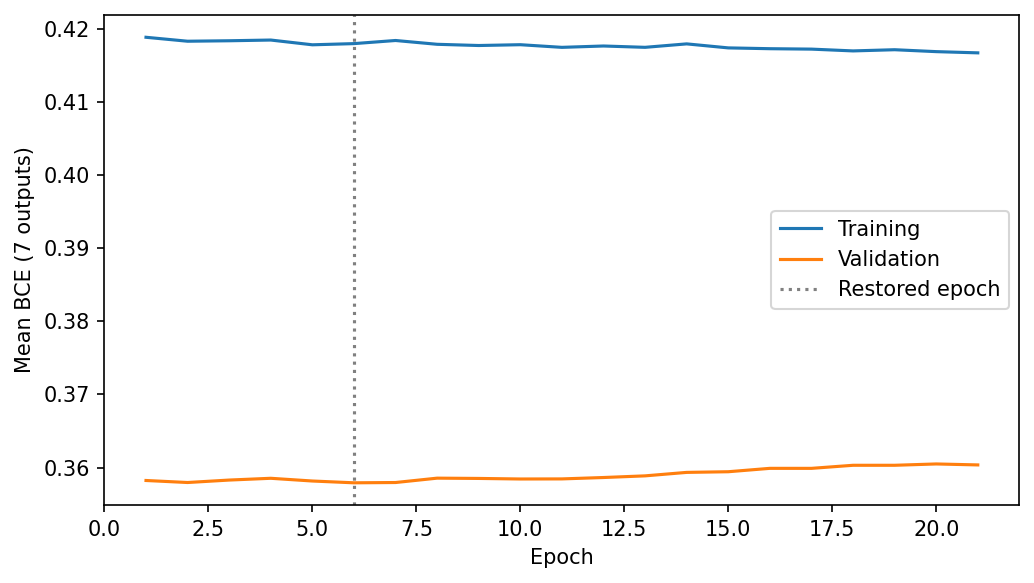

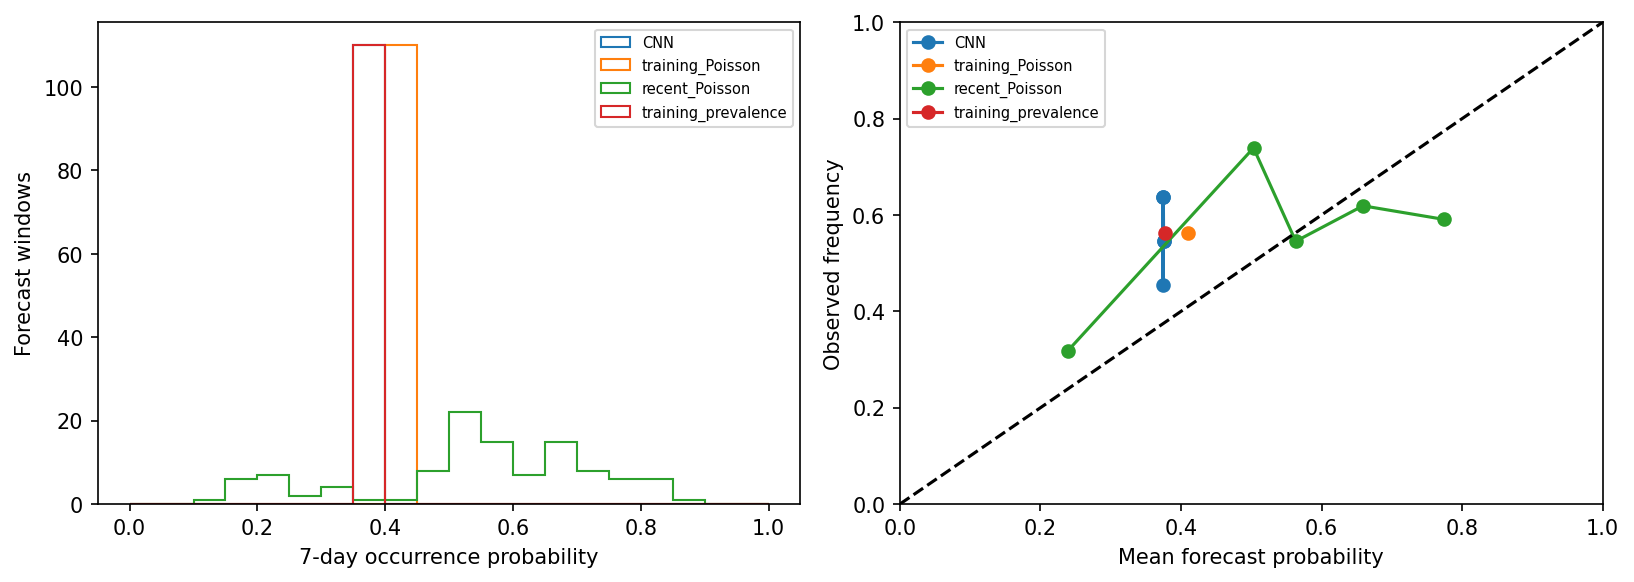

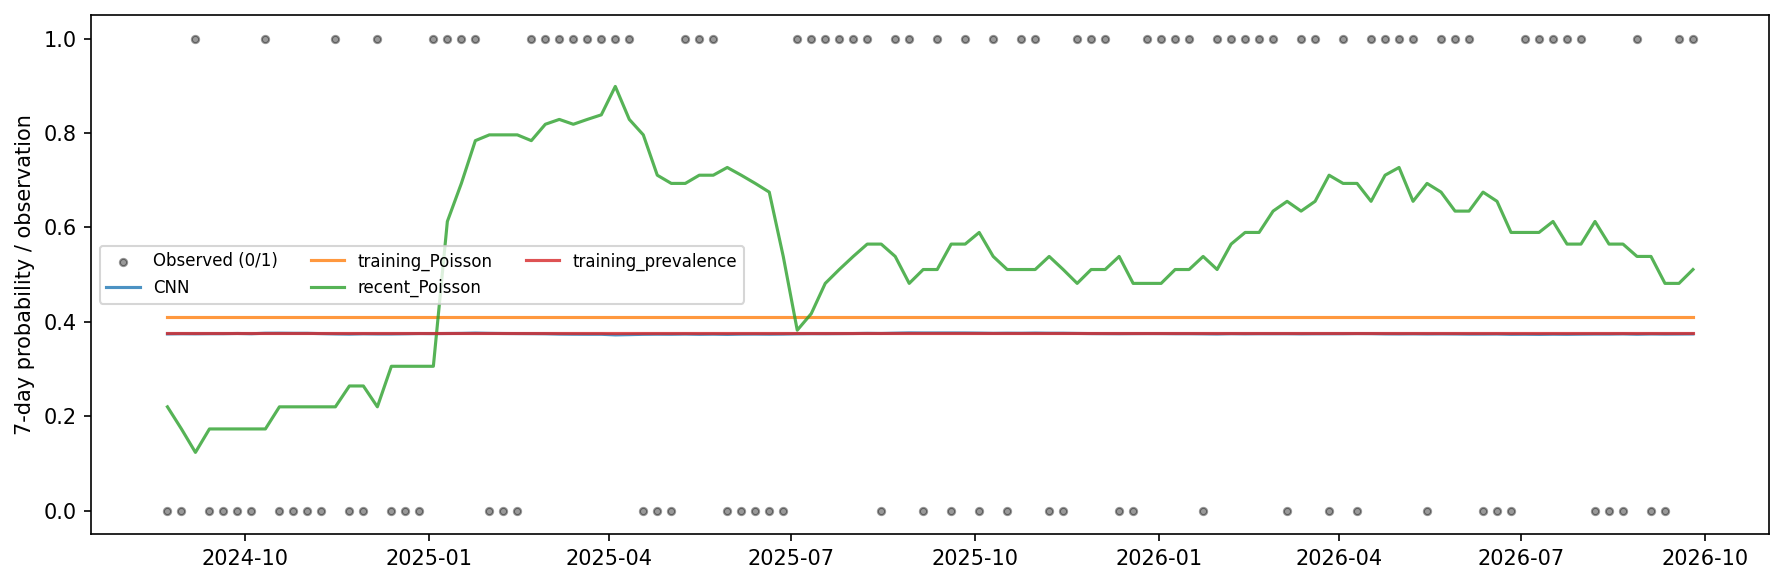

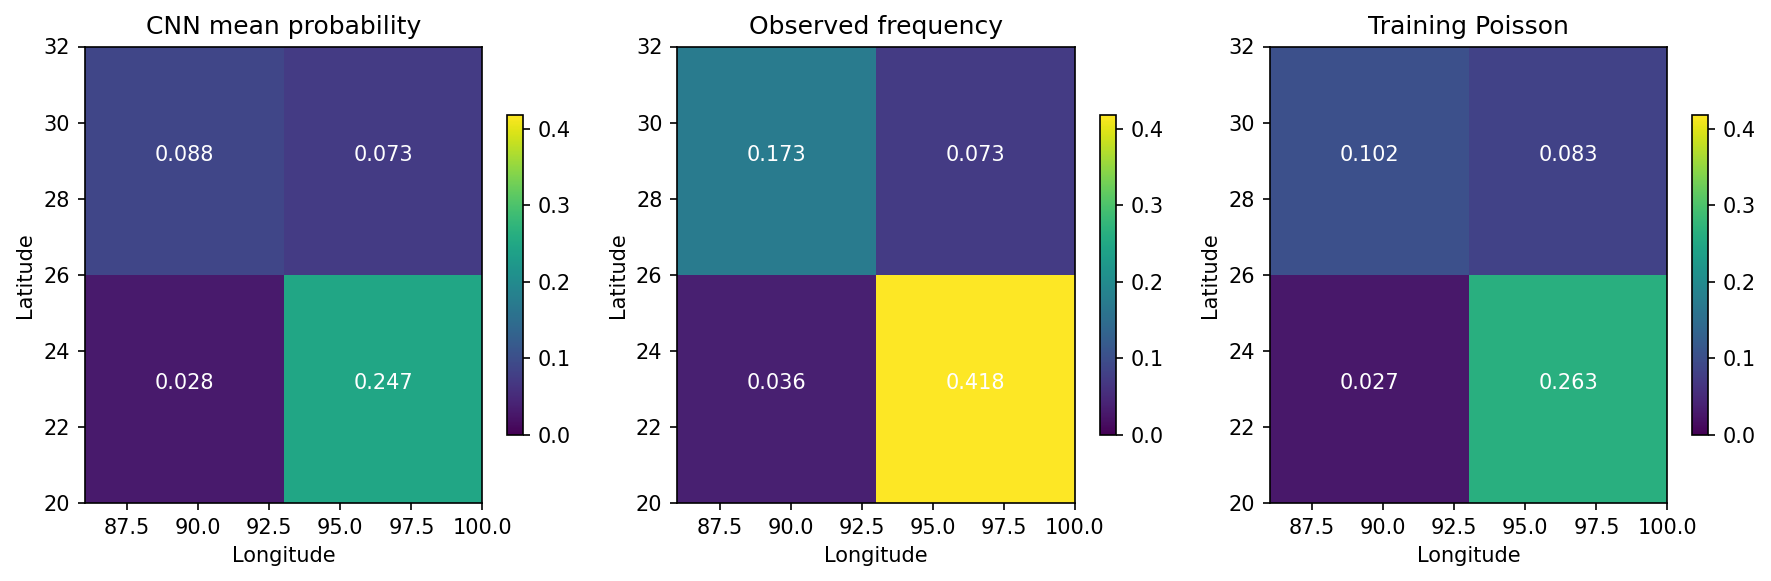

In [10]:
hist=pd.DataFrame(history)
plt.figure(figsize=(7,4)); plt.plot(hist.epoch,hist.train_bce,label='Training'); plt.plot(hist.epoch,hist.validation_bce,label='Validation')
plt.axvline(best_state['epoch'],color='gray',linestyle=':',label='Restored epoch'); plt.xlabel('Epoch'); plt.ylabel('Mean BCE (7 outputs)'); plt.legend(); savefig('training_loss.png')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,p in predictions['test'].items():
    axes[0].hist(p[:,0],bins=np.linspace(0,1,21),histtype='step',label=name)
    obs,forecast=calibration_curve(Y[idx['test'],0],p[:,0],n_bins=5,strategy='quantile')
    axes[1].plot(forecast,obs,'o-',label=name)
axes[0].set(xlabel='7-day occurrence probability',ylabel='Forecast windows'); axes[0].legend(fontsize=7)
axes[1].plot([0,1],[0,1],'k--'); axes[1].set(xlabel='Mean forecast probability',ylabel='Observed frequency',xlim=(0,1),ylim=(0,1)); axes[1].legend(fontsize=7)
savefig('prediction_calibration.png')
calibration=[]
for name,p in predictions['test'].items():
    for j,target in enumerate(TARGETS):
        bins=pd.qcut(pd.Series(p[:,j]),q=5,duplicates='drop')
        if bins.isna().all(): bins=pd.Series(['constant']*len(p))
        for label,inds in bins.groupby(bins,observed=True).groups.items():
            inds=np.asarray(list(inds)); calibration.append(dict(model=name,target=target,bin=str(label),n=len(inds),mean_probability=float(p[inds,j].mean()),observed_frequency=float(Y[idx['test'][inds],j].mean())))
pd.DataFrame(calibration).to_csv(DIRS['metrics']/'calibration_bins.csv',index=False)
plt.figure(figsize=(12,4)); t=manifest.iloc[idx['test']].issue_time
plt.scatter(t,Y[idx['test'],0],s=12,color='black',alpha=.4,label='Observed (0/1)')
for name,p in predictions['test'].items(): plt.plot(t,p[:,0],label=name,alpha=.8)
plt.ylabel('7-day probability / observation'); plt.legend(ncol=3,fontsize=8); savefig('forecast_timeline.png')
fig,axes=plt.subplots(1,3,figsize=(12,4))
maps=[predictions['test']['CNN'][:,3:].mean(axis=0),Y[idx['test'],3:].mean(axis=0),predictions['test']['training_Poisson'][:,3:].mean(axis=0)]
vmax=max(float(a.max()) for a in maps)
for ax,values,title in zip(axes,maps,['CNN mean probability','Observed frequency','Training Poisson']):
    mesh=ax.pcolormesh([86,93,100],[20,26,32],values.reshape(2,2),vmin=0,vmax=vmax,cmap='viridis',shading='flat')
    for c,v in enumerate(values): ax.text([89.5,96.5][c%2],[23,29][c//2],f'{v:.3f}',ha='center',color='white')
    ax.set(title=title,xlabel='Longitude',ylabel='Latitude')
    fig.colorbar(mesh,ax=ax,shrink=.7)
savefig('spatial_forecast.png')

## 16. Comparison against baselines
Lower log loss and Brier score are better; higher average precision indicates better ranking. Threshold precision/recall at 0.5 is secondary and may be zero for rare events. The comparison below includes the primary target, time-window average and cell average. Average spatial scores give equal weight to each cell; they are not location-distance errors. Bootstrap differences below zero favor the CNN, but uncertain differences do not establish improvement.

In [11]:
summary=[]
for name in predictions['test']:
    s=scores[(scores.split=='test')&(scores.model==name)]
    summary.append(dict(model=name,primary_brier=float(s.iloc[0].brier),primary_log_loss=float(s.iloc[0].log_loss),
        primary_AP=float(s.iloc[0].average_precision),time_mean_brier=float(s.iloc[1:3].brier.mean()),
        spatial_mean_brier=float(s.iloc[3:].brier.mean()),all_output_brier=float(s.brier.mean())))
summary=pd.DataFrame(summary); summary.to_csv(DIRS['metrics']/'results_summary.csv',index=False); display(summary)
cnn_brier=float(summary.loc[summary.model.eq('CNN'),'primary_brier'].iloc[0])
beats_all=bool((cnn_brier<summary.loc[~summary.model.eq('CNN'),'primary_brier']).all())
interpretation=('CNN has lower primary test Brier score than all three comparators in this split.' if beats_all else
                'CNN does not beat all simple comparators on primary test Brier score; no general forecasting advantage is established.')
print(interpretation)

,model,primary_brier,primary_log_loss,primary_AP,time_mean_brier,spatial_mean_brier,all_output_brier
0,CNN,0.281609,0.758084,0.567793,0.234552,0.131242,0.182240
1,training_Poisson,0.269457,0.732576,0.563636,0.232346,0.129448,0.178849
2,recent_Poisson,0.242390,0.680387,0.649873,0.225823,0.125200,0.170691
3,training_prevalence,0.280619,0.755973,0.563636,0.236064,0.131875,0.182892


CNN does not beat all simple comparators on primary test Brier score; no general forecasting advantage is established.


## 17. Results and interpretation
The following report is generated only from actual training and held-out predictions. Inspect training/validation loss divergence for overfitting; nearly constant probabilities may indicate insufficient signal or underfitting. A small network and early stopping cannot create information absent from the catalog. Do not infer operational usefulness from training loss or accuracy.

## 18. Limitations
- No magnitude-completeness analysis, independent catalog reconciliation, outage log, or event publication timestamps; reporting changes and retrospective revisions can dominate results.
- Magnitude types are mixed (ML, MB, MW, MC, MS); threshold events are not harmonized Mw events.
- Coverage after 2011 is an assumption. Zero records are labeled zero recorded events, not confirmed physical absence.
- Four broad cells and one magnitude threshold are coarse; marginal outputs are not a coherent joint magnitude/time/location distribution.
- A single temporal holdout and seed, short test span, correlated histories and clustered events limit inference; four-week bootstrap blocks are a sensitivity choice, not an independence guarantee.
- Architecture, start date and targets are exploratory design choices informed by repository and descriptive catalog inspection. No independent prospective test has been performed.
- Homogeneous/recent Poisson baselines ignore aftershock triggering; a validated ETAS comparison and rolling-origin tests remain future work.

## 19. Conclusions
Use proper held-out probability scores and baselines to judge this experiment. A technically verified training run can be complete even when it finds no useful forecasting skill. This is not an earthquake warning system.

## 20. Next steps for BiLSTM comparison
First verify catalog provenance, completeness and reporting delay; harmonize magnitude scales; freeze the same dataset/splits/targets and baseline protocol. Then compare BiLSTM on the same training/validation data, keeping test reuse explicit and reserving a fresh prospective period. Plan multi-seed and rolling-origin evaluation, richer statistical baselines and coherent outputs before claiming model superiority. No later-phase model is implemented here.

### Observed result from the verified run
**2026-11-05:** 5,603 complete-day records from 2011 onward produced 562 training, 110 validation and 110 test samples. Training-only support for M≥4.5 is 212 positive and 350 negative seven-day windows (296 qualifying events); M≥5 has only 75 positive windows, while M≥4 has 392. Fourteen-day M4.5 windows give 171/281 positives and 30-day windows 114/131. Seven days preserves temporal resolution, useful positive/negative balance and more samples. Spatial training positives are SW=15, SE=134, NW=51, NE=40: keep the grid coarse and treat sparse-cell results as exploratory.

The 3,223-parameter model trained for 21 epochs and restored epoch 6. Primary test Brier=0.281609, log loss=0.758084, average precision=0.567793. The recent Poisson baseline is better on all three (0.242390, 0.680387, 0.649873). The CNN forecasts are nearly constant (0.3725–0.3768), whereas observed test occurrence is 62/110=0.5636; this indicates poor adaptation/calibration and weak learned discrimination. At threshold 0.5 the CNN predicts no positives, yielding precision=recall=0 (zero-division convention). The threshold was not tuned after seeing these results.

Validation prevalence was 29/110=0.2636 versus training 212/562=0.3772 and test 0.5636. These changes explain why low validation loss need not imply good test calibration. Training mean BCE changes only slightly while validation worsens after epoch 6; there is mild validation deterioration and a largely climatological solution, not evidence that more epochs would fix the problem. The CNN-minus-recent-rate Brier difference is +0.039219; its four-week block-bootstrap 95% interval [-0.011912, 0.089982] is wide and crosses zero. No robust model-superiority claim is supported. The baseline itself is not validated for operational forecasting.


In [12]:
# Artifact checks and independently reconstructed checkpoint predictions.
clone=CatalogCNN().to(device); clone.load_state_dict(torch.load(best_path,map_location=device,weights_only=False)['model']); clone.eval()
with torch.no_grad(): reloaded=torch.sigmoid(clone(torch.from_numpy(X[idx['test']]).to(device))).cpu().numpy()
assert np.allclose(reloaded,predictions['test']['CNN'],rtol=1e-6,atol=1e-7)
assert not np.allclose(Y[idx['test']],reloaded)
required=[best_path,last_path,DIRS['models']/'preprocessing.json',DIRS['metrics']/'scores.csv',DIRS['reports']/'split_manifest.csv']
assert all(p.exists() and p.stat().st_size>0 for p in required)
assert len(list(DIRS['plots'].glob('*.png')))>=6
verification=dict(notebook_cells_executed_to_final=True,actual_training_epochs=len(history),best_epoch=best_state['epoch'],
    trainable_parameters=n_parameters,input_shape=list(X.shape),output_shape=list(Y.shape),
    all_labels_checked_against_raw_timestamps=True,full_history_and_target_partition_separation=True,
    training_only_scaler=True,reloaded_predictions_match=True,artifact_checks_passed=True)
save_json(DIRS['reports']/'verification.json',verification)
report=f"""# Phase 1 results — {EXPERIMENT}
Date: 2026-11-05. Dataset SHA256: {dataset_hash}.
Raw rows: {len(raw)}; selected complete-day records: {len(events)}.
Samples: { {k:len(v) for k,v in idx.items()} }. Input: {X.shape}; output: {Y.shape}.
Trainable parameters: {n_parameters}. Epochs completed: {len(history)}; restored epoch: {best_state['epoch']}.
Device: {environment['gpu'] or 'CPU'}.

{interpretation}

```
{summary.to_string(index=False)}
```

```
{pd.DataFrame(bootstrap).to_string(index=False)}
```

See split_summary.json for exact dates/event counts, scores.csv for each target, and calibration_bins.csv for reliability support.
Notebook limitations apply: mixed magnitude scales, unknown completeness/delays, exploratory single holdout, coarse marginal outputs and correlated histories.
This run does not establish deterministic or operational earthquake prediction.
"""
(DIRS['reports']/'final_report.md').write_text(report,encoding='utf-8')
registry=json.loads((MEM/'experiment_registry.json').read_text())
for e in registry['experiments']:
    if e['experiment_id']==EXPERIMENT:
        e.update(experiment_status='trained_evaluated_pending_external_verification',epochs=len(history),
                 best_epoch=best_state['epoch'],trainable_parameters=n_parameters,results=summary.to_dict(orient='records'))
save_json(MEM/'experiment_registry.json',registry)
checkpoint_memory('T8 evaluation completed; T9 external notebook verification/documentation pending.',
                  f'Experiment {EXPERIMENT}; epoch {len(history)}; best epoch {best_state["epoch"]}.\nBest: {best_path.relative_to(BASE)}.\nReport: {(DIRS["reports"]/"final_report.md").relative_to(BASE)}.\nAll in-notebook assertions passed. Next: validate saved executed notebook, update status/task graph.')
print(report)

# Phase 1 results — cnn_b86050c74334
Date: 2026-11-05. Dataset SHA256: 5cfebe7268a87940ec9489d4f72b45381e2c940cc3f38d96d60b4575355d8bf3.
Raw rows: 8089; selected complete-day records: 5603.
Samples: {'train': 562, 'validation': 110, 'test': 110}. Input: (782, 12, 90); output: (782, 7).
Trainable parameters: 3223. Epochs completed: 21; restored epoch: 6.
Device: NVIDIA GeForce RTX 3050 Laptop GPU.

CNN does not beat all simple comparators on primary test Brier score; no general forecasting advantage is established.

```
              model  primary_brier  primary_log_loss  primary_AP  time_mean_brier  spatial_mean_brier  all_output_brier
                CNN       0.281609          0.758084    0.567793         0.234552            0.131242          0.182240
   training_Poisson       0.269457          0.732576    0.563636         0.232346            0.129448          0.178849
     recent_Poisson       0.242390          0.680387    0.649873         0.225823            0.125200          0.17